In [1]:
%pip install -q transformers tiktoken

import os
from urllib.request import urlretrieve

if not os.path.exists("input.txt"):
    urlretrieve(
        "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",
        "input.txt",
    )
print("input.txt hazır:", os.path.getsize("input.txt"), "bayt")


input.txt hazır: 1115394 bayt


## Görev 1

In [2]:
# Hazır GPT-2'yi incele. Hugging Face'ten GPT-2 (124M) ağırlıklarını yükle. Her ağırlığın adını ve boyutunu yazdır, toplam parametre sayısını hesapla. Pozisyon embedding'lerini (wpe) çiz: ne görüyorsun, kendi cümlelerinle yaz. (0:03:39 - 0:13:47)

In [3]:
from transformers import GPT2LMHeadModel

In [4]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2") # 124M
sd_hf = model_hf.state_dict() # raw tensors

for k, v in sd_hf.items():
    print(k, v.shape)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

In [5]:
# 50257 token ve dimensional embedding
# 1024 positions maximum sequence lenght 1024 token geçmişe gidebilir. 768 optimizasyon tarafından öğrenilmiş vektör.

In [6]:
sd_hf["transformer.wpe.weight"].view(-1)[:20]

tensor([-0.0188, -0.1974,  0.0040,  0.0113,  0.0638, -0.1050,  0.0369, -0.1680,
        -0.0491, -0.0565, -0.0025,  0.0135, -0.0042,  0.0151,  0.0166, -0.1381,
        -0.0063, -0.0461,  0.0267, -0.2042])

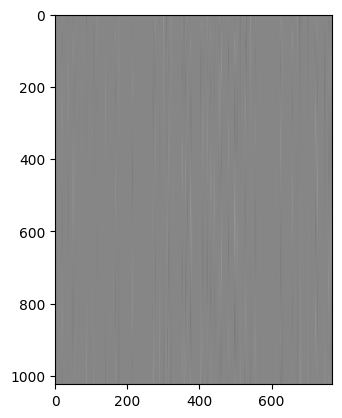

In [7]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.imshow(sd_hf["transformer.wpe.weight"], cmap="gray")

In [8]:
# yukarıdaki görüntü neyi açıklıyor: wpe nin yani word position embeddings in öğrendiği konum vektörlerinin tablosu diyebiliriz. Gpt 2 nin contentine yani
# içeriğine ek olarak dizide nerede olduğunu da bilmek zorunda bu yüzden her konum için vektör öğreniyor. Satırlar konum stünlar ise vektörün boyutudur. Buradaki dizi
# dedğimiz ise sequential length modele tek seferde verdiğimiz token sayısı geçen hafta tokenizer ile öğrenmiştik.
# Örneğin "Bedia'dan geldi hediyeler" derken farklı tokenizerlar ile "Bedia, 'dan, geldi, hediyeler" diye de  ayırabilir "Bedia, ', dan, geldi, hediyeler"

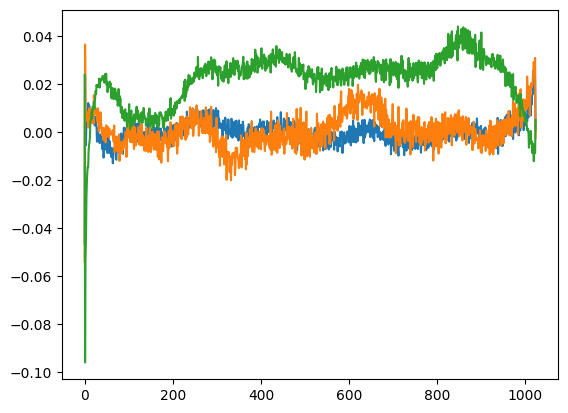

In [9]:
plt.plot(sd_hf["transformer.wpe.weight"][:, 150])
plt.plot(sd_hf["transformer.wpe.weight"][:, 200])
plt.plot(sd_hf["transformer.wpe.weight"][:, 250])

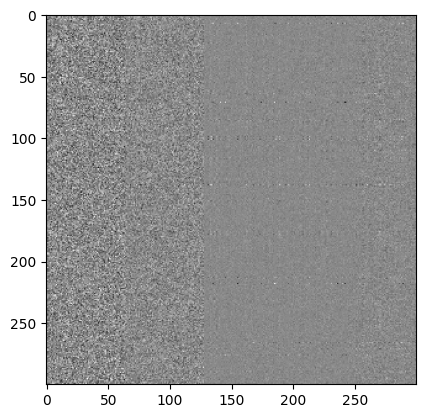

In [10]:
plt.imshow(sd_hf["transformer.h.1.attn.c_attn.weight"][:300,:300], cmap="gray")
# 1. layerdaki self attention  q, k, v leri hesaplayan katmanının ağırlıkları matris olarak 300  satır ve stünuna bakılması

In [11]:
from transformers import pipeline, set_seed
generator = pipeline('text-generation', model='gpt2')
set_seed(42)
generator("Hello, I'm a language model,", max_length=30, num_return_sequences=5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': "Hello, I'm a language model, so I can write things that are easy to understand with a little bit of code. But when you think of"},
 {'generated_text': "Hello, I'm a language model, I've had a lot of good experiences with it, I'm a native speaker. I've been working with"},
 {'generated_text': 'Hello, I\'m a language model, I\'m an editor," the writer said. "But I don\'t think that\'s a good idea. I'},
 {'generated_text': 'Hello, I\'m a language model, and it\'s not about me. It\'s about people.\n\n"If you\'re a person and you'},
 {'generated_text': "Hello, I'm a language model, not a language model. I'm thinking of the languages in which we have formal semantics. One of my favorite"}]

## Görev 2

In [12]:
# GPT-2'yi kendin yaz ve ağırlıkları yükle. Hafta 8'deki GPT'nden yola çıkarak GPT-2 modülünü yaz. Hugging Face ağırlıklarını kendi modeline yükle. Aynı girdi için kendi modelinin logits'inin Hugging Face modelininkiyle aynı çıktığını göster. Hafta 8'deki GPT'nden farklarını madde madde yaz, örneğin aktivasyon fonksiyonu ve q, k, v'nin tek katmanda hesaplanması. Bazı ağırlıkları yüklerken neden transpoze etmen gerektiğini de yaz. (0:13:47 - 0:31:00)

In [13]:
import os
import math
import time
import inspect
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F

# -----------------------------------------------------------------------------

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y



class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x



class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

# ----------------------------------------------------------------------------------------

model = GPT.from_pretrained('gpt2')
print("didin't crash yay!")

loading weights from pretrained gpt: gpt2


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

didin't crash yay!


In [14]:
from transformers import GPT2TokenizerFast

tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
input_ids = tokenizer(
    "Hello, I'm a language model,",
    return_tensors="pt"
).input_ids

device = next(model.parameters()).device
model = model.to(device)
model_hf = model_hf.to(device)
input_ids = input_ids.to(device)

model.eval()
model_hf.eval()

with torch.no_grad():
    logits_kendi, _ = model(input_ids)
    logits_hf = model_hf(input_ids).logits

print("Kendi modelimin logits boyutu:", logits_kendi.shape)
print("Hugging Face logits boyutu:", logits_hf.shape)
print("En büyük fark:", (logits_kendi - logits_hf).abs().max().item())
print("Yakın sonuç mu?:", torch.allclose(
    logits_kendi, logits_hf, atol=1e-4, rtol=1e-4
))

Kendi modelimin logits boyutu: torch.Size([1, 8, 50257])
Hugging Face logits boyutu: torch.Size([1, 8, 50257])
En büyük fark: 7.62939453125e-05
Yakın sonuç mu?: True


In [15]:
# Modelin boyutu: hafta 8 de küçük boyutlarala başlayıp tek head attention multi head, feedforward residual layernorm ve dropout eklemiştik.
# Buradaki gpt2 de ise h.0 ile h.11 ağırlıkların 12 adet trasformer bloğu kullanılmasını söylüyor. Bir bloğun çıktısı bir sonraki bloğa aktarılıyor.
# 12 bloğu, 12 head’i ve 768 boyutlu kullanılıyor ve feedforwarda ReLU yerine GELU var. GELU kullanılmasının nedeni, tamamen gpt 2 yi doğru kopyalamak, ancak ikisinin farkını söyleyelim, GELU, relu daha yumuşak geçiş yapıyor yani Relu negatif değerleri 0 a çevirirken GELU ise negatif değerleri tamamen kesmek yerine küçültüyor ve gradyanın tamamen kaybolmamasını sağlar.
# x = x + self.attn(self.ln_1(x)) x = x + self.mlp(self.ln_2(x)) önce LayerNorm uygulanıyor, sonra attention ya da MLP çalışıyor elde edilen sonuç eski x’e ekleniyor. Bu ekleme residual bağlantı oluyor. Residual bağlantı, bilginin bir alt katmandan diğerine doğrudan taşınmasını sağlar.
# Böylece katmanlar girdiyi tamamen baştan oluşturmak zorunda kalmaz; mevcut temsilin üzerine ekleme yapar. Çok sayıda blok üst üste geldiğinde eğitimin ve gradyan akışının daha sağlıklı olmasına yardım eder. Geçen haftalardan hatırlayacağımız üzere bu çok katmanlı yapılarda daha çok işimize yarayacaktır.
# q, k, v  tek seferde hesaplanıyor. 8. haftada öğrendiğimiz, headin amacı her head kendi tokenına bakarak attention hesabı yapıyordu. Bu sefer tek seferde tek matris çarpımı ile yapılıyor bunu amacı ayrı ayrı matris çarpımları yapmaktansa verimliliği artırmak ve tek seferde yapmak.
# 'attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight', 'mlp.c_proj.weight' bu ağırlıkların transpoze edilmesinin sebebi hugging face de bu katmanların ağırlık matrisinini nn.Linear' in beklediğinin tam tersi olması sebebiyle transpoze alıyoruz

## Görev 3

In [16]:
# Modeli konuştur. Sampling döngüsünü yaz, top-k ile örnek üret. Önce İngilizce bir başlangıç cümlesi dene, sonra Türkçe bir cümle. GPT-2'nin Türkçe çıktısı neden kötü? Aynı Türkçe cümle GPT-2'nin tokenizer'ında kaç token tutuyor? Geçen haftaki sonuçlarınla bağla. (0:31:00 - 0:45:50)

In [17]:
num_return_sequences = 5
max_length = 30

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Kullanılan cihaz:", device)

model = GPT.from_pretrained('gpt2')
model.eval()
model.to(device)

import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch. long) # (8,)
tokens = tokens.unsqueeze(0). repeat(num_return_sequences, 1) # (5, 8)
x = tokens.to(device)


# generate! right now x is (B, T) where B = 5, T = 8
# set the seed to 42
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get the logits
    with torch.no_grad() :
        logits, _ = model(x) # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1, :] # (B, vocab_size)
        # get the probabilities
        probs = F.softmax (logits, dim=-1)
        # do top-k sampling of 50 (huggingface pipeline default)
        # topk_probs here becomes (5, 50), topk_indices is (5, 50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probabilities
        ix = torch.multinomial(topk_probs,1) # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix) # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)


# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)


Kullanılan cihaz: cuda
loading weights from pretrained gpt: gpt2


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

> Hello, I'm a language model, not a program.

So this morning I started studying for the interview in the lab. This was not
> Hello, I'm a language model, and one of the main things that bothers me when they create languages is how easy it becomes to create something that
> Hello, I'm a language model, and I wrote it off on the grounds that a language model would make me more fluent. But I'm not
> Hello, I'm a language model, I really like languages. I like languages because like, they're good. And the way we talk about languages
> Hello, I'm a language model, a language model I'm using for data modelling. All I did was test the results and then I wrote some


In [18]:
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Merhaba! ben bir dil modeliyim,")
tokens = torch.tensor(tokens, dtype=torch. long) # (8,)
tokens = tokens.unsqueeze(0). repeat(num_return_sequences, 1) # (5, 8)
x = tokens.to(device)


# generate! right now x is (B, T) where B = 5, T = 8
# set the seed to 42
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get the logits
    with torch.no_grad() :
        logits, _ = model(x) # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1, :] # (B, vocab_size)
        # get the probabilities
        probs = F.softmax (logits, dim=-1)
        # do top-k sampling of 50 (huggingface pipeline default)
        # topk_probs here becomes (5, 50), topk_indices is (5, 50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probabilities
        ix = torch.multinomial(topk_probs,1) # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix) # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)


# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)


> Merhaba! ben bir dil modeliyim, na konah! [A: [You should let her see who your boyfriend is.]
> Merhaba! ben bir dil modeliyim, zey shalim uyik pakilas. I love this house, you
> Merhaba! ben bir dil modeliyim, kyenin na vozakim prawiye mikulin.

> Merhaba! ben bir dil modeliyim, habiliyim, hababahliyim, hababaeliyim
> Merhaba! ben bir dil modeliyim, bana dura, ubi' sokir, na' zaman dara!


In [19]:
turkce_cumle = "Merhaba! ben bir dil modeliyim,"
ingilizce_cumle = "Hello! I am a language model."

tokenlar_turkce = enc.encode(turkce_cumle)
tokenlar_ingilizce = enc.encode(ingilizce_cumle)

print("Türkçe Token Sayısı:", len(tokenlar_turkce))
print("İngilizce Token Sayısı:", len(tokenlar_ingilizce))
print("Token parçaları:", [enc.decode([token]) for token in tokenlar_turkce])
print("Token parçaları:", [enc.decode([token]) for token in tokenlar_ingilizce])

Türkçe Token Sayısı: 11
İngilizce Token Sayısı: 8
Token parçaları: ['Mer', 'hab', 'a', '!', ' ben', ' bir', ' dil', ' model', 'iy', 'im', ',']
Token parçaları: ['Hello', '!', ' I', ' am', ' a', ' language', ' model', '.']


In [20]:
# Türkçede başarılı olmamasının sebebi hiç bilmemesi değil, ingilizceye göre daha az öğrenmiş olması. Eğitim verisinin ağırlıklı olarak ingilizce olduğunu da unutmayalım.
# gpt 2 tokenizerında ingilizce 8 Türkçe 11 token tutuyor. Geçen hafta  gpt 4 deseni ile tokenizer bölme işlemini yapmıştı bu hafta ise gpt 2 nin tokenızerını kullandık.
# Model her ürettiği token’ı girdiye ekleyip sıradakini tahmin ediyor;
# dolayısıyla 8 token’lık İngilizce girişte ilk tahmin 9., 11 token’lık Türkçe girişte ilk tahmin 12. token oluyor.

## Görev 4

In [21]:
# İlk eğitim adımları. Modeli rastgele başlat ve ilk loss'u ölç, ln(50257) ≈ 10.8 ile karşılaştır. Neden bu değere yakın çıkmalı, kendi cümlelerinle yaz. Sonra tek bir batch'i ezberlet: aynı batch'te birkaç yüz adım eğit, loss sıfıra yaklaşmalı. Bu test neden işe yarıyor? (0:45:50 - 1:02:00)

In [22]:
with open('input.txt', 'r') as f:
    text = f.read()
data = text[:1000]
print(data[:100])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You


In [23]:
!wc input.txt # satır, kelime, byte sayıları sırasıyla.

  40000  202651 1115394 input.txt


In [24]:
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode(data)
print(tokens[:24])

[5962, 22307, 25, 198, 8421, 356, 5120, 597, 2252, 11, 3285, 502, 2740, 13, 198, 198, 3237, 25, 198, 5248, 461, 11, 2740, 13]


In [25]:
import torch
buf = torch.tensor(tokens[:24 + 1])
x = buf[:-1].view(4, 6)
y = buf[1:].view(4, 6)
print(x)
print(y)

tensor([[ 5962, 22307,    25,   198,  8421,   356],
        [ 5120,   597,  2252,    11,  3285,   502],
        [ 2740,    13,   198,   198,  3237,    25],
        [  198,  5248,   461,    11,  2740,    13]])
tensor([[22307,    25,   198,  8421,   356,  5120],
        [  597,  2252,    11,  3285,   502,  2740],
        [   13,   198,   198,  3237,    25,   198],
        [ 5248,   461,    11,  2740,    13,   198]])


In [26]:
# get a data bacth
enc = tiktoken.get_encoding('gpt2')

with open('input.txt', 'r') as f:
    text = f.read()
text = text[:1000]
tokens = enc.encode(text)
B, T = 4, 32
buf = torch.tensor(tokens[:B * T + 1], device=device)
x = buf[:-1].view(B, T)
y = buf[1:].view(B, T)

# get logits
model = GPT(GPTConfig())
model.to(device)
logits, loss = model(x, y)

print(logits.shape)
print(loss)

torch.Size([4, 32, 50257])
tensor(10.9276, device='cuda:0', grad_fn=<NllLossBackward0>)


In [27]:
# 4 örneğin ve her örnekte 32 sequence lengthin ve onun da içinde modein 50257 logits puanı bulunur
# Modelin çıkması gereken lossunu matematiksel olarak hesapladığımızda 1/50257 olması gerek.
# Model, öğrenmediği için başlangıçta tüm tokenlara eşit şans vermesi gerektiğini bekleriz.
# -loss = -ln(1 / 50257) = ln(50257)  = 10.824 çıkması gerekir bizim lossumuz da 10.9276 çıktı

In [28]:
# get a data bacth
enc = tiktoken.get_encoding('gpt2')

with open('input.txt', 'r') as f:
    text = f.read()
text = text[:1000]
tokens = enc.encode(text)

B, T = 4, 32
buf = torch.tensor(tokens[:B * T + 1])
buf = buf.to(device)
x = buf[:-1].view(B, T)
y = buf[1:].view(B, T)

# get logits
model = GPT(GPTConfig())
model.to(device)

# optimize
optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(500):
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    print(f"step {i}, loss: {loss.item()}")



step 0, loss: 11.039794921875
step 1, loss: 6.663155555725098
step 2, loss: 4.3436079025268555
step 3, loss: 2.6632027626037598
step 4, loss: 1.5427072048187256
step 5, loss: 0.8597838282585144
step 6, loss: 0.47356438636779785
step 7, loss: 0.27063167095184326
step 8, loss: 0.1773259937763214
step 9, loss: 0.11996451020240784
step 10, loss: 0.08219090104103088
step 11, loss: 0.06204281374812126
step 12, loss: 0.04921121522784233
step 13, loss: 0.03784191608428955
step 14, loss: 0.03081672266125679
step 15, loss: 0.027196265757083893
step 16, loss: 0.024225454777479172
step 17, loss: 0.021008910611271858
step 18, loss: 0.018178068101406097
step 19, loss: 0.015978410840034485
step 20, loss: 0.014266790822148323
step 21, loss: 0.012912779115140438
step 22, loss: 0.011753318831324577
step 23, loss: 0.010669667273759842
step 24, loss: 0.009659357368946075
step 25, loss: 0.008765056729316711
step 26, loss: 0.008000337518751621
step 27, loss: 0.00735181150957942
step 28, loss: 0.006800493225

In [ ]:
# step 499, loss: 0.0003466063062660396 loss 0 a yaklaştı model tek bir batchi 500 adımda gittikçe daha çok ezberledi. Bu test, modeli test etmek ve hata ayıklamak için yapılıyor. Eğer burada başarılı olmasaydık lossun düştüğünü yani ezberleyemediğini görmeseydik o zaman modelimizi kurarkenki yapıda sorun olduğunu anlayabilirdik.


## Görev 5

In [30]:
# Ek, erken bitirenler için, ikisinden biri. (a) Videonun devamına geç: küçük bir data loader yaz ve metnin tamamında eğit, weight tying'i ekle ve kaç parametre kazandırdığını hesapla, başlangıç değerlerini videodaki gibi ayarla. (1:02:00 - 1:22:18) (b) GPT-2'nin ağırlıklarını yükledikten sonra birkaç Türkçe cümlenin loss'unu ölç, aynı cümlelerin İngilizcesiyle karşılaştır. Fark neden bu kadar büyük?

In [31]:
class DataLoaderLite:
    def __init__(self, B, T):
        self.B = B
        self.T = T
        # at init load tokens from disk and store them in memory
        with open('input.txt','r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B * T)} batches")

        # state
        self. current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]

        x = (buf[:-1]).view(B, T) # inputs
        y = (buf[1:]).view(B, T) # targets
        # advance the position in the tensor
        self.current_position += B * T
        # if loading the next batch would be out of bounds, reset
        if self.current_position + (B * T + 1) > len(self. tokens):
            self.current_position = 0
        return x, y


In [32]:
print(sd_hf["lm_head.weight"].shape)
print(sd_hf["transformer.wte.weight"]. shape)

torch.Size([50257, 768])
torch.Size([50257, 768])


In [33]:
(sd_hf["lm_head.weight"] == sd_hf["transformer.wte.weight"]).all()

tensor(True)

In [34]:
print(sd_hf["lm_head.weight"].data_ptr()) # data pointer is also equal
print(sd_hf["transformer.wte.weight"].data_ptr())

137964210868179
137964210868179


In [35]:
train_loader = DataLoaderLite(B = 4, T = 32)


# get logits

model = GPT(GPTConfig())
model.to(device)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(500):
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    print(f"step {i}, loss: {loss.item()}")

loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 11.044963836669922
step 1, loss: 9.697427749633789
step 2, loss: 8.691420555114746
step 3, loss: 9.041369438171387
step 4, loss: 8.445714950561523
step 5, loss: 8.168761253356934
step 6, loss: 8.914657592773438
step 7, loss: 8.655176162719727
step 8, loss: 8.01738166809082
step 9, loss: 7.829100131988525
step 10, loss: 8.360072135925293
step 11, loss: 7.171414375305176
step 12, loss: 7.678493022918701
step 13, loss: 7.213716506958008
step 14, loss: 7.370395660400391
step 15, loss: 7.126316070556641
step 16, loss: 7.247105598449707
step 17, loss: 8.250958442687988
step 18, loss: 6.986501693725586
step 19, loss: 7.693273067474365
step 20, loss: 7.442963600158691
step 21, loss: 7.537785053253174
step 22, loss: 6.2312469482421875
step 23, loss: 6.5674333572387695
step 24, loss: 6.621920585632324
step 25, loss: 6.249640464782715
step 26, loss: 6.355886459350586
step 27, loss: 7.473291397094727
step 28, loss: 6.920680999755859
step 29

In [36]:
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y


class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x



class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight

        # init params
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

In [37]:
# standard deviation grows inside the residual stream
x = torch.zeros(768)
n = 100 # e.g. 100 layers
for i in range(n):
    x += torch.randn(768)
print(x.std())

tensor(9.8123)


In [38]:
# standard deviation grows inside the residual stream
x = torch.zeros(768)
n = 100 # e.g. 100 layers
for i in range(n):
    x += n**-0.5 * torch.randn(768)
print(x.std())

tensor(1.0066)


In [39]:
torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 32)


# get logits

model = GPT(GPTConfig())
model.to(device)
print("Weight tying aktif mi?:", model.transformer.wte.weight is model.lm_head.weight)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(500):
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    print(f"step {i}, loss: {loss.item()}")


loaded 338025 tokens
1 epoch = 2640 batches
Weight tying aktif mi?: True
step 0, loss: 10.960028648376465
step 1, loss: 9.687705993652344
step 2, loss: 9.08289909362793
step 3, loss: 9.145988464355469
step 4, loss: 8.626201629638672
step 5, loss: 8.33169937133789
step 6, loss: 8.89795207977295
step 7, loss: 8.837980270385742
step 8, loss: 8.116044998168945
step 9, loss: 8.042159080505371
step 10, loss: 8.380849838256836
step 11, loss: 7.435605049133301
step 12, loss: 7.8245649337768555
step 13, loss: 7.4589409828186035
step 14, loss: 7.531876564025879
step 15, loss: 7.366677284240723
step 16, loss: 7.436797142028809
step 17, loss: 8.293567657470703
step 18, loss: 7.202800273895264
step 19, loss: 7.887031078338623
step 20, loss: 7.505932807922363
step 21, loss: 7.822871685028076
step 22, loss: 6.425383567810059
step 23, loss: 6.877798557281494
step 24, loss: 6.827328681945801
step 25, loss: 6.701854705810547
step 26, loss: 6.814748764038086
step 27, loss: 7.6212263107299805
step 28, los

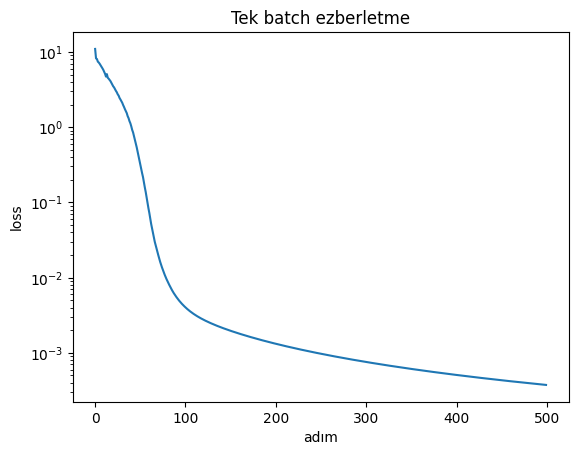

ilk loss: 10.9600  |  son loss: 0.000375


In [42]:
import matplotlib.pyplot as plt

torch.manual_seed(1337)
model = GPT(GPTConfig()).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

enc = tiktoken.get_encoding('gpt2')
with open('input.txt', 'r') as f:
    text = f.read()[:1000]
tokens = enc.encode(text)
B, T = 4, 32
buf = torch.tensor(tokens[:B * T + 1], device=device)
x, y = buf[:-1].view(B, T), buf[1:].view(B, T)

losses = []
for i in range(500):
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

plt.plot(losses)
plt.yscale('log')
plt.xlabel('adım')
plt.ylabel('loss')
plt.title('Tek batch ezberletme')
plt.show()
print(f"ilk loss: {losses[0]:.4f}  |  son loss: {losses[-1]:.6f}")

In [40]:
# GPT-2 (124M) PARAMETRE SAYISINI

  #   vocab_size = 50257   -> modelin bildiği token sayısı
  #   block_size = 1024    -> modelin bir seferde görebildiği en uzun cümle (token cinsinden)
  #   n_embd     = 768     -> her token'ı temsil eden vektörün uzunluğu
  #   n_layer    = 12      -> üst üste dizilen Block sayısı
  #
  # Temel kural: bir nn.Linear(giriş, çıkış) katmanının parametre sayısı
  #   giriş x çıkış (ağırlıklar) + çıkış (bias) kadardır.
  # Bir LayerNorm'un parametre sayısı 2 x n_embd'dir
  # GELU, softmax gibi fonksiyonların öğrenilen parametresi yoktur, hesaba girmezler.
  #
  # 1) TOKEN EMBEDDING (wte)
  #    Her token için 768 sayılık bir vektör tutulur.
  #    50257 x 768 = 38.597.376 parametre
  #
  # 2) POZİSYON EMBEDDING (wpe)
  #     Her pozisyon (1024 tane) için 768 sayılık bir vektör tutulur.
  #          1024 x 768 = 786.432 parametre

  # 3) BİR BLOCK İÇİNDE
    #    a) ln_1 (LayerNorm)               : 2 x 768            =     1.536
    #    b) attn.c_attn (768 -> 3x768)     : 768 x 2304 + 2304  = 1.771.776
    #       (q, k ve v'yi tek seferde üretir, o yüzden çıkış 3 x 768 = 2304)
    #    c) attn.c_proj (768 -> 768)       : 768 x 768 + 768    =   590.592
    #    d) ln_2 (LayerNorm)               : 2 x 768            =     1.536
    #    e) mlp.c_fc (768 -> 4x768)        : 768 x 3072 + 3072  = 2.362.368
    #       (MLP içinde boyut 4 katına çıkar, 4 x 768 = 3072)
    #    f) mlp.c_proj (3072 -> 768)       : 3072 x 768 + 768   = 2.360.064
    #    ------------------------------------------------------------------
    #    Bir Block toplamı: 1.536 + 1.771.776 + 590.592 + 1.536 + 2.362.368 + 2.360.064
    #                     = 7.087.872 parametre
    #
    # 4) 12 BLOCK
    #    12 x 7.087.872 = 85.054.464 parametre
    #
    # 5) SON LAYERNORM (ln_f)
    #    2 x 768 = 1.536 parametre
    #
    # 6) ÇIKIŞ KATMANI (lm_head), bias yok
    #    768 x 50257 = 38.597.376 parametre
    #    (ağırlığı wte ile aynı boyutta, bu yüzden aşağıdaki weight tying mümkün)
    #
    # ------------------------------------------------------------------
    # WEIGHT TYING OLMADAN (wte ve lm_head ayrı ayrı öğreniliyor)
    #    38.597.376 + 786.432 + 85.054.464 + 1.536 + 38.597.376
    #    = 163.037.184 parametre  (yaklaşık 163 milyon)
    #
    # WEIGHT TYING İLE (lm_head, wte ile AYNI matrisi kullanıyor)
    #    38.597.376 + 786.432 + 85.054.464 + 1.536
    #    = 124.439.808 parametre  (yaklaşık 124 milyon, GPT-2 small'un resmi boyutu)
    #
    # KAZANÇ
    #    163.037.184 - 124.439.808 = 38.597.376 parametre
    #    Bu tam olarak 50257 x 768'dir, yani ikinci matrisin tamamı.
    #    Toplamın yaklaşık %23,7'si (38.597.376 / 163.037.184) kadar parametre tasarruf edilir.
